<a href="https://colab.research.google.com/github/manikanta-eng/python-project/blob/main/Electronic_Component_Recognizer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Using Colab cache for faster access to the 'electronic-component-recognizer' dataset.
Dataset path: /kaggle/input/electronic-component-recognizer


Verifying images:   0%|          | 0/3259 [00:00<?, ?it/s]


===== DATASET AUDIT =====
Total images found        : 3259
Corrupt/unreadable removed: 0
Number of classes         : 20
Width  min/mean/max       : 19 1095 7682
Height min/mean/max       : 19 928 5833
Imbalance ratio (max/min) : 2.34
Exact duplicate images    : 544 (16.69%)
Same image, diff. labels  : 11


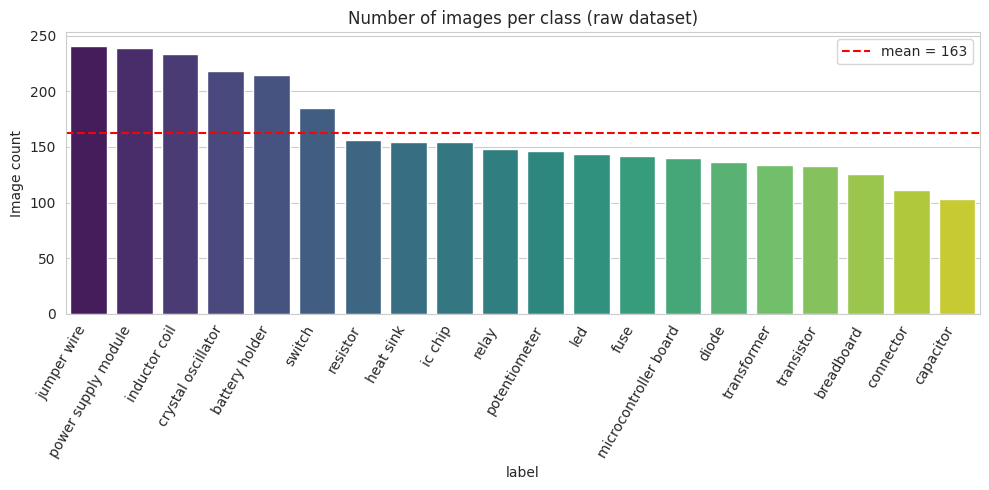

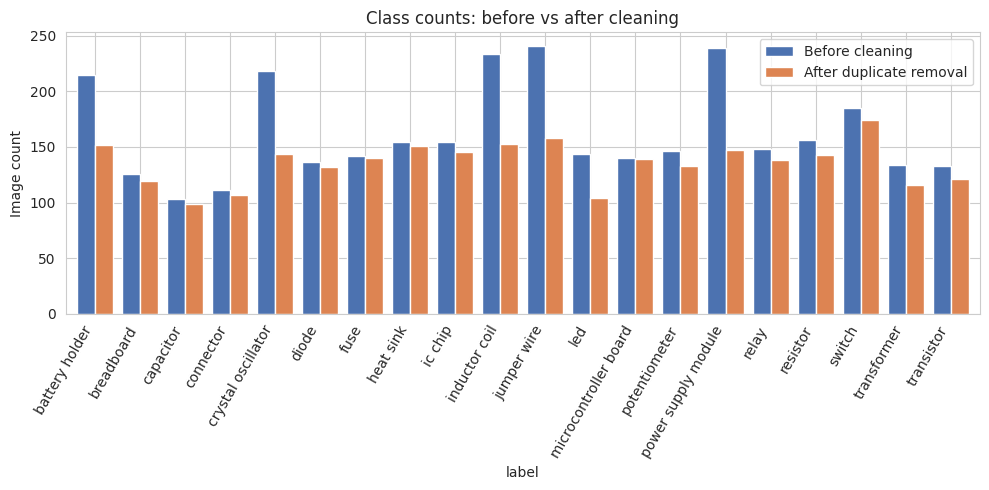

Loading images:   0%|          | 0/2715 [00:00<?, ?it/s]


Train 1899 | Validation 408 | Test 408 | Classes 20


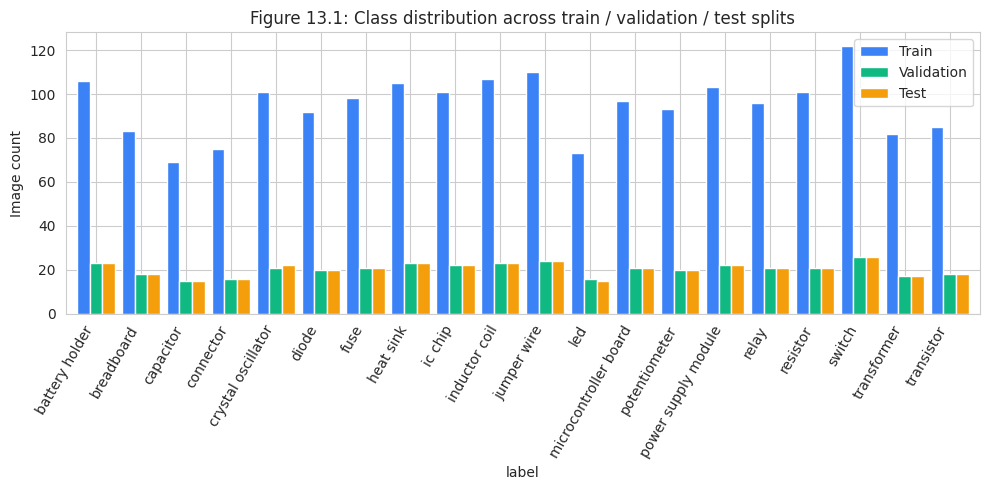

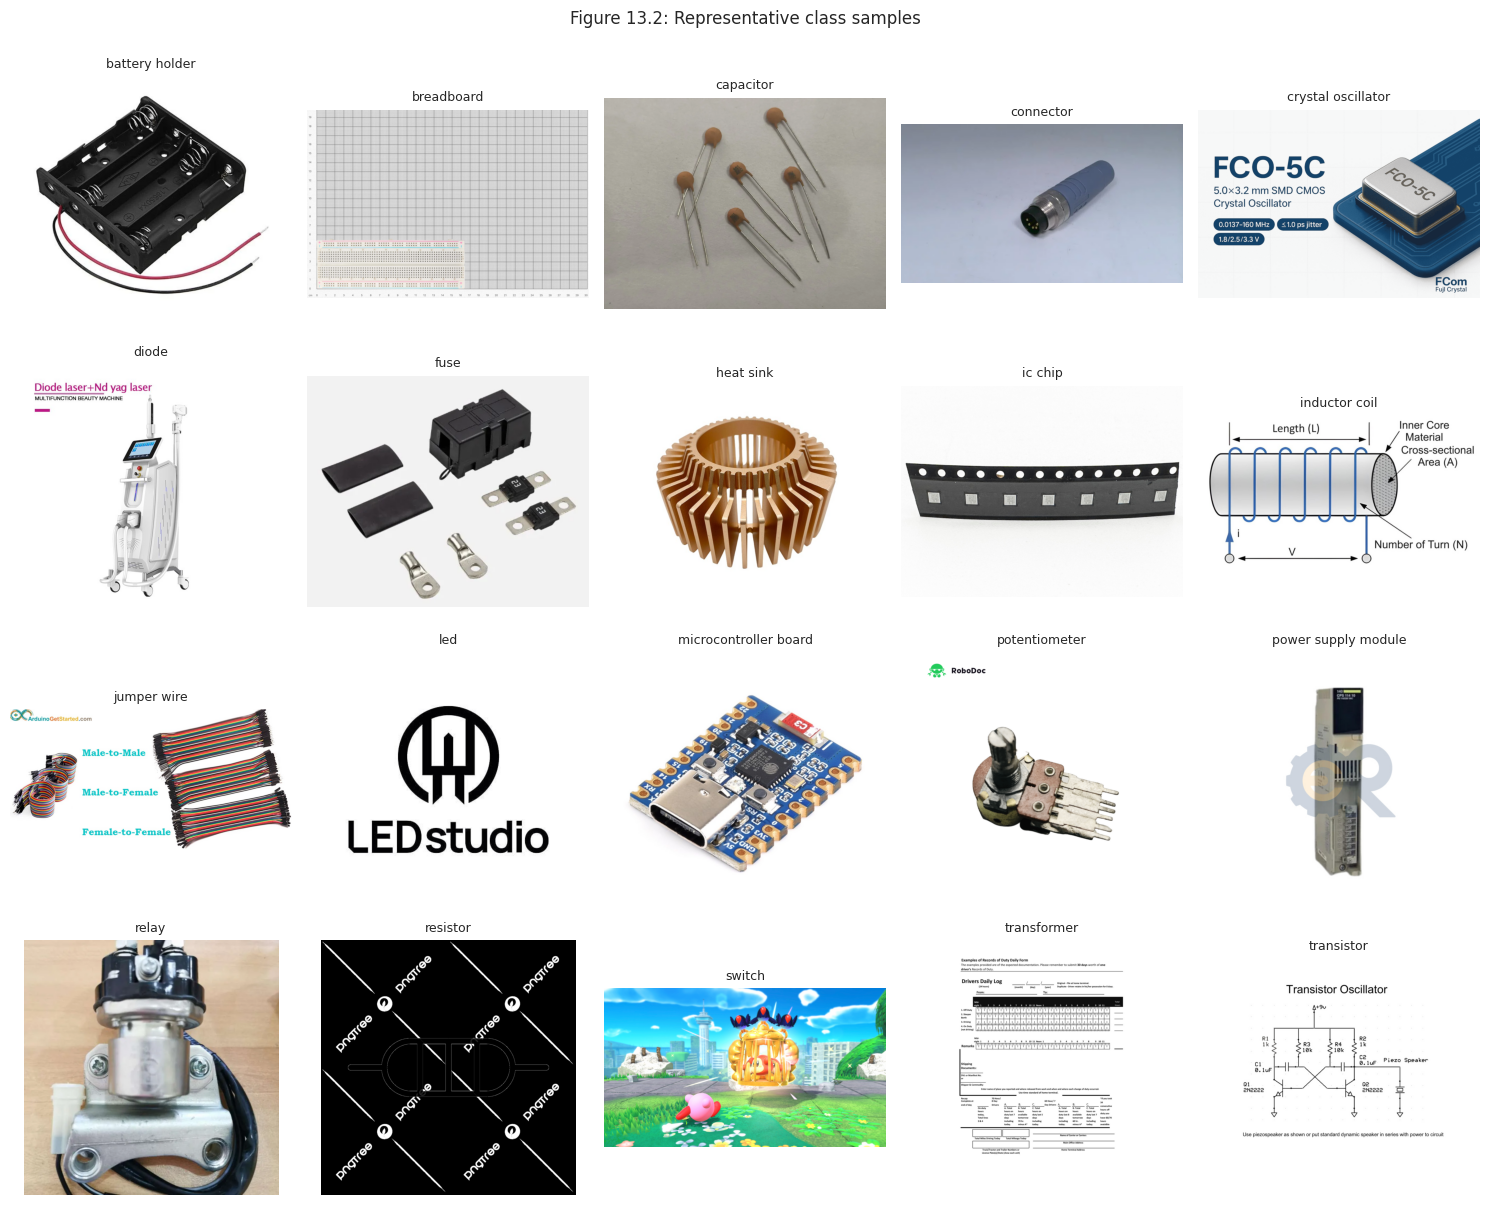


===== 5. EXPERIMENTAL SETUP =====


,Component,Detail
0,Hardware,CPU
1,Framework,PyTorch 2.14.1+cpu + torchvision 0.29.1+cpu
2,Batch size,32
3,Epochs (baseline),20 per model
4,Optimizer (baseline),"Adam, lr 0.001 (new head, frozen pretrained ba..."
5,Loss function,Cross-entropy loss
6,Precision,Mixed precision (torch.autocast / GradScaler)
7,Evaluation libraries,"scikit-learn, Grad-CAM (manual), SHAP"



Training EfficientNet-B0
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 144MB/s] 


[EfficientNet-B0] epoch 01/20 | train loss 2.7671 acc 0.2080 | val loss 2.5109 acc 0.3309


In [ ]:
# =====================================================================
# Electronic Component Recognizer: Comparative Deep Learning Report
# Same structure/outputs as Assignment_2 (7 models, selection, 3 optimizations, XAI)
# Google Colab: Runtime -> Change runtime type -> T4 GPU, then run this ONE cell.
# =====================================================================
!pip -q install kagglehub shap

import os, gc, math, time, copy, hashlib, random, warnings, shutil
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
from concurrent.futures import ThreadPoolExecutor
from IPython.display import display
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
from torchvision import models as tvm
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             roc_auc_score, confusion_matrix, classification_report)
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')

# ------------------------------ CONFIG -------------------------------
SEED = 42
EPOCHS = 20            # per model (set 5 for a quick test)
BATCH = 32
IMG = 224              # InceptionV3 is upsampled to 299 on the GPU
MAX_PER_CLASS = None   # e.g. 300 to speed things up on a huge dataset
BASE_LR = 1e-3         # baseline: Adam on the new classification head (backbone frozen)
FT_LR, FT_WD = 5e-5, 1e-4   # optimization 1: AdamW fine-tuning
AUX_W = 0.4            # auxiliary loss weight (InceptionV3 / GoogLeNet)
XAI_CLASSES = 6        # how many classes to show in Grad-CAM / SHAP figures

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = dev.type == 'cuda'
if not USE_AMP:
    print('WARNING: no GPU found. Runtime -> Change runtime type -> T4 GPU')
if USE_AMP:
    torch.cuda.manual_seed_all(SEED)

FIG_DIR = '/content/figures'
shutil.rmtree(FIG_DIR, ignore_errors=True); os.makedirs(FIG_DIR, exist_ok=True)
def save_show(name):
    plt.tight_layout()
    plt.savefig(f'{FIG_DIR}/{name}.png', dpi=150, bbox_inches='tight')
    plt.show()

# =====================================================================
# 3. DATASET: DOWNLOAD, AUDIT, CLEANING
# (if credentials are requested: upload kaggle.json, then run
#  !mkdir -p ~/.kaggle && mv kaggle.json ~/.kaggle && chmod 600 ~/.kaggle/kaggle.json)
# =====================================================================
import kagglehub
DATA_DIR = kagglehub.dataset_download('mdfaisalahmed025/electronic-component-recognizer')
print('Dataset path:', DATA_DIR)

EXT = {'.jpg', '.jpeg', '.png', '.bmp'}
SPLITS = {'train', 'training', 'val', 'valid', 'validation', 'test', 'testing'}

def scan(p):
    try:
        with Image.open(p) as im:
            im.verify()
        with Image.open(p) as im:
            w, h = im.size
        parent = p.parent
        if parent.name.lower() in SPLITS:          # handle train/val/test folder layouts
            parent = parent.parent
        return dict(path=str(p), label=parent.name, width=w, height=h,
                    md5=hashlib.md5(p.read_bytes()).hexdigest())
    except Exception:
        return None

files = [p for p in Path(DATA_DIR).rglob('*') if p.is_file() and p.suffix.lower() in EXT]
with ThreadPoolExecutor(8) as ex:
    out = list(tqdm(ex.map(scan, files), total=len(files), desc='Verifying images'))
rows = [r for r in out if r]
n_corrupt = len(out) - len(rows)
df = pd.DataFrame(rows)
assert df.label.nunique() >= 2, 'Could not find class folders. Check the dataset structure printed above.'

print('\n===== DATASET AUDIT =====')
print('Total images found        :', len(df))
print('Corrupt/unreadable removed:', n_corrupt)
print('Number of classes         :', df.label.nunique())
print('Width  min/mean/max       :', df.width.min(), int(df.width.mean()), df.width.max())
print('Height min/mean/max       :', df.height.min(), int(df.height.mean()), df.height.max())
counts = df.label.value_counts()
print('Imbalance ratio (max/min) :', round(counts.max() / counts.min(), 2))

dup_mask = df.duplicated('md5', keep='first')
print('Exact duplicate images    :', int(dup_mask.sum()), f'({dup_mask.mean() * 100:.2f}%)')
print('Same image, diff. labels  :', int((df.groupby('md5').label.nunique() > 1).sum()))
df_clean = df[~dup_mask].reset_index(drop=True)
if MAX_PER_CLASS:
    df_clean = df_clean.groupby('label').head(MAX_PER_CLASS).reset_index(drop=True)
counts_clean = df_clean.label.value_counts()

NW = max(10, 0.45 * df.label.nunique())
plt.figure(figsize=(NW, 5))
ax = sns.barplot(x=counts.index, y=counts.values, palette='viridis')
plt.axhline(counts.mean(), color='red', ls='--', label=f'mean = {counts.mean():.0f}')
plt.title('Number of images per class (raw dataset)'); plt.ylabel('Image count')
plt.xticks(rotation=60, ha='right'); plt.legend(); save_show('00_class_counts_raw')

cmp_df = pd.DataFrame({'Before cleaning': counts, 'After duplicate removal': counts_clean}).fillna(0)
cmp_df.plot(kind='bar', figsize=(NW, 5), width=.8, color=['#4c72b0', '#dd8452'])
plt.title('Class counts: before vs after cleaning'); plt.ylabel('Image count')
plt.xticks(rotation=60, ha='right'); save_show('00_before_after_cleaning')

# =====================================================================
# 4. PREPROCESSING + DATASET SPLIT (70 / 15 / 15, stratified)
# =====================================================================
def to_rgb(im):
    if im.mode in ('RGBA', 'LA') or (im.mode == 'P' and 'transparency' in im.info):
        im = im.convert('RGBA')
        bg = Image.new('RGB', im.size, (255, 255, 255)); bg.paste(im, mask=im.split()[-1])
        return bg
    return im.convert('RGB')

def load_arr(p):
    try:
        with Image.open(p) as im:
            return np.asarray(to_rgb(im).resize((IMG, IMG), Image.BILINEAR), dtype=np.uint8)
    except Exception as e:
        print('Skipped', p, '->', e); return None

with ThreadPoolExecutor(8) as ex:
    arrs = list(tqdm(ex.map(load_arr, df_clean.path), total=len(df_clean), desc='Loading images'))
keep = [i for i, a in enumerate(arrs) if a is not None]
X_all = torch.from_numpy(np.stack([arrs[i] for i in keep])).permute(0, 3, 1, 2).contiguous()  # uint8 N,3,H,W
del arrs
df_clean = df_clean.iloc[keep].reset_index(drop=True)
df_clean['idx'] = np.arange(len(df_clean))

class_names = sorted(df_clean.label.unique()); NUM = len(class_names)
df_clean['y'] = df_clean.label.map({c: i for i, c in enumerate(class_names)})

def split(d, size):
    try:
        return train_test_split(d, test_size=size, stratify=d.y, random_state=SEED)
    except ValueError:
        return train_test_split(d, test_size=size, random_state=SEED)

tv_df, te_df = split(df_clean, 0.15)
tr_df, va_df = split(tv_df, 0.15 / 0.85)
Xtr, Xva, Xte = X_all[tr_df.idx.values], X_all[va_df.idx.values], X_all[te_df.idx.values]
Ytr, Yva, Yte = [torch.tensor(d.y.values, dtype=torch.long) for d in (tr_df, va_df, te_df)]
y_te = Yte.numpy()
print(f'\nTrain {len(tr_df)} | Validation {len(va_df)} | Test {len(te_df)} | Classes {NUM}')

# Figure 13.1: class distribution across splits
sp = pd.DataFrame({'Train': tr_df.label.value_counts(), 'Validation': va_df.label.value_counts(),
                   'Test': te_df.label.value_counts()}).fillna(0).loc[class_names]
sp.plot(kind='bar', figsize=(NW, 5), width=.85, color=['#3b82f6', '#10b981', '#f59e0b'])
plt.title('Figure 13.1: Class distribution across train / validation / test splits')
plt.ylabel('Image count'); plt.xticks(rotation=60, ha='right'); save_show('13_1_class_distribution')

# Figure 13.2: representative samples
n = min(NUM, 20); cols = 5; rws = int(np.ceil(n / cols))
plt.figure(figsize=(3 * cols, 3 * rws))
for i, c in enumerate(class_names[:n]):
    im = Image.open(df_clean[df_clean.label == c].sample(1, random_state=SEED).path.iloc[0]).convert('RGB')
    plt.subplot(rws, cols, i + 1); plt.imshow(im); plt.title(c, fontsize=9); plt.axis('off')
plt.suptitle('Figure 13.2: Representative class samples', y=1.0)
save_show('13_2_samples')

# ---- GPU augmentation: h-flip, +-15 deg rotation, colour jitter, ImageNet normalisation
MEAN = torch.tensor([0.485, 0.456, 0.406], device=dev).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=dev).view(1, 3, 1, 1)

def augment(x):
    B = x.size(0)
    flip = (torch.rand(B, device=dev) < 0.5).view(B, 1, 1, 1)
    x = torch.where(flip, x.flip(3), x)
    ang = (torch.rand(B, device=dev) * 2 - 1) * 15 * math.pi / 180
    c, s, z = torch.cos(ang), torch.sin(ang), torch.zeros_like(ang)
    theta = torch.stack([torch.stack([c, -s, z], 1), torch.stack([s, c, z], 1)], 1)
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    x = F.grid_sample(x, grid, padding_mode='reflection', align_corners=False)
    j = lambda: 1 + (torch.rand(B, 1, 1, 1, device=dev) * 2 - 1) * 0.2
    x = x * j()
    m = x.mean((1, 2, 3), keepdim=True); x = (x - m) * j() + m
    g = x.mean(1, keepdim=True); x = (x - g) * j() + g
    return x.clamp(0, 1)

def prep(xb, name, train):
    x = xb.to(dev, non_blocking=True).float() / 255.
    if train: x = augment(x)
    if name == 'InceptionV3':
        x = F.interpolate(x, size=(299, 299), mode='bilinear', align_corners=False)
    return (x - MEAN) / STD

# =====================================================================
# 5. EXPERIMENTAL SETUP
# =====================================================================
setup = pd.DataFrame({'Component': ['Hardware', 'Framework', 'Batch size', 'Epochs (baseline)',
                                    'Optimizer (baseline)', 'Loss function', 'Precision', 'Evaluation libraries'],
                      'Detail': [(torch.cuda.get_device_name(0) if USE_AMP else 'CPU'),
                                 f'PyTorch {torch.__version__} + torchvision {torchvision.__version__}',
                                 BATCH, f'{EPOCHS} per model',
                                 f'Adam, lr {BASE_LR} (new head, frozen pretrained backbone)',
                                 'Cross-entropy loss', 'Mixed precision (torch.autocast / GradScaler)',
                                 'scikit-learn, Grad-CAM (manual), SHAP']})
print('\n===== 5. EXPERIMENTAL SETUP ====='); display(setup)

# =====================================================================
# 6. THE SEVEN MODELS
# =====================================================================
MODEL_NAMES = ['EfficientNet-B0', 'ResNet50', 'DenseNet121', 'MobileNetV3-L',
               'InceptionV3', 'ViT-B/16', 'GoogLeNet']

def build(name, freeze):
    if name == 'EfficientNet-B0':
        m = tvm.efficientnet_b0(weights=tvm.EfficientNet_B0_Weights.DEFAULT)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, NUM); heads = [m.classifier]
    elif name == 'ResNet50':
        m = tvm.resnet50(weights=tvm.ResNet50_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, NUM); heads = [m.fc]
    elif name == 'DenseNet121':
        m = tvm.densenet121(weights=tvm.DenseNet121_Weights.DEFAULT)
        m.classifier = nn.Linear(m.classifier.in_features, NUM); heads = [m.classifier]
    elif name == 'MobileNetV3-L':
        m = tvm.mobilenet_v3_large(weights=tvm.MobileNet_V3_Large_Weights.DEFAULT)
        m.classifier[3] = nn.Linear(m.classifier[3].in_features, NUM); heads = [m.classifier]
    elif name == 'InceptionV3':
        m = tvm.inception_v3(weights=tvm.Inception_V3_Weights.DEFAULT, aux_logits=True)
        m.fc = nn.Linear(m.fc.in_features, NUM)
        m.AuxLogits.fc = nn.Linear(m.AuxLogits.fc.in_features, NUM); heads = [m.fc, m.AuxLogits]
    elif name == 'ViT-B/16':
        m = tvm.vit_b_16(weights=tvm.ViT_B_16_Weights.DEFAULT)
        m.heads.head = nn.Linear(m.heads.head.in_features, NUM); heads = [m.heads]
    elif name == 'GoogLeNet':
        m = tvm.googlenet(weights=tvm.GoogLeNet_Weights.DEFAULT, aux_logits=True)
        m.fc = nn.Linear(m.fc.in_features, NUM)
        m.aux1.fc2 = nn.Linear(m.aux1.fc2.in_features, NUM)
        m.aux2.fc2 = nn.Linear(m.aux2.fc2.in_features, NUM); heads = [m.fc, m.aux1, m.aux2]
    if freeze:
        for p in m.parameters(): p.requires_grad = False
        for h in heads:
            for p in h.parameters(): p.requires_grad = True
    return m.to(dev)

def count_params_m(m):   # excludes auxiliary classifiers (used only during training)
    return sum(p.numel() for n_, p in m.named_parameters() if 'aux' not in n_.lower()) / 1e6

# =====================================================================
# 7. TRAINING + EVALUATION
# =====================================================================
def make_scaler():
    if not USE_AMP: return None
    try: return torch.amp.GradScaler('cuda')
    except Exception: return torch.cuda.amp.GradScaler()

def run_epoch(model, name, X, Y, train, crit, opt=None, scaler=None):
    model.train(train)
    n = len(X); idx = torch.randperm(n) if train else torch.arange(n)
    tl, tc, cnt = 0., 0, 0
    for i in range(0, n, BATCH):
        b = idx[i:i + BATCH]
        if train and len(b) < 2: continue
        xb = prep(X[b], name, train); yb = Y[b].to(dev)
        with torch.set_grad_enabled(train):
            with torch.autocast(device_type=dev.type, dtype=torch.float16, enabled=USE_AMP):
                out = model(xb)
                if isinstance(out, tuple):
                    main = out[0]
                    loss = crit(main, yb)
                    if train:
                        loss = loss + AUX_W * sum(crit(a, yb) for a in out[1:] if a is not None)
                else:
                    main = out; loss = crit(main, yb)
        if train:
            opt.zero_grad(set_to_none=True)
            if scaler is not None:
                scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            else:
                loss.backward(); opt.step()
        with torch.no_grad():
            tl += F.cross_entropy(main.float(), yb, reduction='sum').item()
            tc += (main.argmax(1) == yb).sum().item(); cnt += len(b)
    return tl / max(cnt, 1), tc / max(cnt, 1)

def fit(name, epochs, freeze, opt_kind, lr, wd=0., sched=None, class_w=None, tag=''):
    model = build(name, freeze)
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=wd) if opt_kind == 'adamw' else torch.optim.Adam(params, lr=lr)
    scheduler = None
    if sched == 'cosine': scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    if sched == 'plateau': scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode='min', factor=0.5, patience=2)
    crit_tr = nn.CrossEntropyLoss(weight=class_w.to(dev) if class_w is not None else None)
    crit_ev = nn.CrossEntropyLoss()
    scaler = make_scaler()
    hist = dict(train_loss=[], val_loss=[], train_acc=[], val_acc=[])
    best_acc, best_state = -1, None
    t0 = time.time()
    for ep in range(1, epochs + 1):
        trl, tra = run_epoch(model, name, Xtr, Ytr, True, crit_tr, opt, scaler)
        vl, va = run_epoch(model, name, Xva, Yva, False, crit_ev)
        if scheduler is not None:
            scheduler.step(vl) if sched == 'plateau' else scheduler.step()
        for k, v in zip(hist, (trl, vl, tra, va)): hist[k].append(v)
        if va > best_acc:
            best_acc = va; best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        print(f'[{tag or name}] epoch {ep:02d}/{epochs} | train loss {trl:.4f} acc {tra:.4f} | '
              f'val loss {vl:.4f} acc {va:.4f}')
    model.load_state_dict(best_state)       # best checkpoint by validation accuracy
    return model, hist, time.time() - t0

@torch.no_grad()
def predict(model, name, X, bs=64):
    model.eval(); P = []
    for i in range(0, len(X), bs):
        with torch.autocast(device_type=dev.type, dtype=torch.float16, enabled=USE_AMP):
            out = model(prep(X[i:i + bs], name, False))
        if isinstance(out, tuple): out = out[0]
        P.append(F.softmax(out.float(), 1).cpu())
    return torch.cat(P).numpy()

def safe_auc(y, P):            # macro one-vs-rest ROC-AUC, skipping classes absent from the test set
    aucs = []
    for k in range(NUM):
        yk = (y == k)
        if 0 < yk.sum() < len(y): aucs.append(roc_auc_score(yk, P[:, k]))
    return float(np.mean(aucs)) if aucs else float('nan')

def metrics(y, P):
    pred = P.argmax(1)
    p, r, f, _ = precision_recall_fscore_support(y, pred, average='macro', zero_division=0)
    return {'Accuracy': accuracy_score(y, pred), 'Precision': p, 'Recall': r, 'F1': f, 'ROC-AUC': safe_auc(y, P)}

@torch.no_grad()
def infer_ms(model, name):
    model.eval(); x = prep(Xte[:BATCH], name, False)
    def go():
        with torch.autocast(device_type=dev.type, dtype=torch.float16, enabled=USE_AMP):
            model(x)
    for _ in range(3): go()
    if USE_AMP: torch.cuda.synchronize()
    t = time.time()
    for _ in range(10): go()
    if USE_AMP: torch.cuda.synchronize()
    return (time.time() - t) / (10 * len(x)) * 1000

def cleanup():
    gc.collect()
    if USE_AMP: torch.cuda.empty_cache()

records, hists = [], {}
for name in MODEL_NAMES:
    print(f'\n{"=" * 72}\nTraining {name}\n{"=" * 72}')
    model, h, secs = fit(name, EPOCHS, True, 'adam', BASE_LR, tag=name)
    P = predict(model, name, Xte)
    rec = {'Model': name, **metrics(y_te, P), 'Params (M)': round(count_params_m(model), 1),
           'Infer. (ms)': round(infer_ms(model, name), 2), 'Train time (min)': round(secs / 60, 1)}
    records.append(rec); hists[name] = h
    del model; cleanup()

res = pd.DataFrame(records).set_index('Model')

# =====================================================================
# 8. SEVEN-MODEL COMPARATIVE ANALYSIS
# =====================================================================
print('\n===== 8. SEVEN-MODEL COMPARATIVE ANALYSIS =====')
display(res.round(3))
res.round(4).to_csv('/content/seven_model_results.csv')

# Figure 18.1
cols_ = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']
lo = max(0, np.floor((res[cols_].min().min() - 0.03) * 50) / 50)
res[cols_].plot(kind='bar', figsize=(13, 5.5)); plt.ylim(lo, 1.0)
plt.title('Figure 18.1: Seven-model performance comparison'); plt.xlabel('Model')
plt.xticks(rotation=30, ha='right'); save_show('18_1_performance')

# Figure 18.2
fig, ax1 = plt.subplots(figsize=(11, 5))
ax1.bar(res.index, res['Params (M)'], color='#93b8fb', width=.5); ax1.set_ylabel('Params (M)')
ax1.set_xlabel('Model'); ax1.tick_params(axis='x', rotation=60)
ax2 = ax1.twinx(); ax2.plot(res.index, res['Infer. (ms)'], 'o-', color='#ef4444', lw=2.5)
ax2.set_ylabel('Inference time (ms/img)'); ax2.grid(False)
plt.title('Figure 18.2: Efficiency comparison, model size vs inference speed'); save_show('18_2_efficiency')

# Figures 18.3 / 18.4
for key, ylab, title, fn in [('val_acc', 'Validation accuracy', 'Figure 18.3: Validation accuracy, all seven models', '18_3_val_acc'),
                             ('val_loss', 'Validation loss', 'Figure 18.4: Validation loss, all seven models', '18_4_val_loss')]:
    plt.figure(figsize=(11, 6))
    for nme in MODEL_NAMES:
        plt.plot(range(1, len(hists[nme][key]) + 1), hists[nme][key], marker='o', ms=3, label=nme)
    plt.xlabel('Epoch'); plt.ylabel(ylab); plt.title(title); plt.legend(ncol=2); save_show(fn)

# Figure 18.5
fig, axes = plt.subplots(2, 7, figsize=(26, 7))
for j, nme in enumerate(MODEL_NAMES):
    h = hists[nme]; ep = range(1, len(h['train_loss']) + 1)
    axes[0, j].plot(ep, h['train_loss'], label='train'); axes[0, j].plot(ep, h['val_loss'], label='val')
    axes[0, j].set_title(f'{nme}\nLoss', fontsize=10)
    axes[1, j].plot(ep, h['train_acc'], label='train'); axes[1, j].plot(ep, h['val_acc'], label='val')
    axes[1, j].set_title('Accuracy', fontsize=10); axes[1, j].set_xlabel('Epoch')
axes[0, 0].legend(); fig.suptitle('Figure 18.5: Per-model training vs validation loss and accuracy', fontsize=14)
save_show('18_5_per_model_curves')

# =====================================================================
# 9. BEST-MODEL SELECTION (composite score)
# =====================================================================
mm = lambda s: (s - s.min()) / (s.max() - s.min() + 1e-12)
res['Composite'] = (0.35 * mm(res['Accuracy']) + 0.25 * mm(res['F1']) + 0.15 * mm(res['ROC-AUC'].fillna(0))
                    + 0.15 * (1 - mm(res['Params (M)'])) + 0.10 * (1 - mm(res['Infer. (ms)'])))
best = res['Composite'].idxmax()
print('\n===== 9. BEST-MODEL SELECTION =====')
print('Composite = 0.35 Accuracy + 0.25 F1 + 0.15 ROC-AUC + 0.15 (1 - norm. params) + 0.10 (1 - norm. inference time)')
display(res[['Accuracy', 'F1', 'ROC-AUC', 'Params (M)', 'Infer. (ms)', 'Composite']].sort_values('Composite', ascending=False).round(3))
b = res.loc[best]
print(f'Result: {best} achieved the highest composite score (accuracy {b.Accuracy * 100:.1f}%, F1 {b.F1:.3f}, '
      f'{b["Params (M)"]}M params, {b["Infer. (ms)"]} ms/image). Selected as the final model for optimization.')
plt.figure(figsize=(9, 4.5))
res['Composite'].sort_values().plot(kind='barh', color='#6366f1'); plt.title('Composite selection score')
save_show('09_composite_score')

# Figure 18.6
h = hists[best]; ep = range(1, len(h['train_loss']) + 1)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(ep, h['train_loss'], 'o-', label='Train'); ax[0].plot(ep, h['val_loss'], 'o-', label='Val')
ax[0].set_title(f'Loss (best model: {best})'); ax[0].set_xlabel('Epoch'); ax[0].legend()
ax[1].plot(ep, h['train_acc'], 'o-', label='Train'); ax[1].plot(ep, h['val_acc'], 'o-', label='Val')
ax[1].set_title(f'Accuracy (best model: {best})'); ax[1].set_xlabel('Epoch'); ax[1].legend()
fig.suptitle('Figure 18.6: Best-model training/validation curves'); save_show('18_6_best_model_curves')

# =====================================================================
# 10. THREE OPTIMIZATION TECHNIQUES (cumulative, on the best model)
# =====================================================================
counts_tr = np.bincount(Ytr.numpy(), minlength=NUM).astype('float32')
class_w = torch.tensor(counts_tr.sum() / (NUM * np.maximum(counts_tr, 1)), dtype=torch.float32)

stages = [('Opt1: Fine-tune+Cosine LR', dict(freeze=False, opt_kind='adamw', lr=FT_LR, wd=FT_WD, sched='cosine')),
          ('Opt2: Class-weighted loss', dict(freeze=False, opt_kind='adamw', lr=FT_LR, wd=FT_WD, sched='cosine', class_w=class_w)),
          ('Opt3: AMP+Plateau LR',      dict(freeze=False, opt_kind='adamw', lr=FT_LR, wd=FT_WD, sched='plateau', class_w=class_w))]

stage_hist = {'Baseline': hists[best]}
stage_rows = [{'Stage': 'Baseline', **{k: res.loc[best, k] for k in ('Accuracy', 'F1', 'ROC-AUC')},
               'Train time (min)': res.loc[best, 'Train time (min)']}]
final_model, final_P = None, None
for i, (label, kw) in enumerate(stages):
    print(f'\n{"=" * 72}\n{label}  [{best}]\n{"=" * 72}')
    model, h, secs = fit(best, EPOCHS, tag=label, **kw)
    P = predict(model, best, Xte); m_ = metrics(y_te, P)
    stage_hist[label] = h
    stage_rows.append({'Stage': label, 'Accuracy': m_['Accuracy'], 'F1': m_['F1'],
                       'ROC-AUC': m_['ROC-AUC'], 'Train time (min)': round(secs / 60, 1)})
    if i == len(stages) - 1:
        final_model, final_P = model, P
    else:
        del model; cleanup()

stage_df = pd.DataFrame(stage_rows).set_index('Stage')
print('\n===== 11. BASELINE VERSUS OPTIMIZED-MODEL COMPARISON =====')
display(stage_df.round(3)); stage_df.round(4).to_csv('/content/optimization_results.csv')

# Figure 21.1
lo = max(0, np.floor((stage_df[['Accuracy', 'F1', 'ROC-AUC']].min().min() - 0.02) * 50) / 50)
stage_df[['Accuracy', 'F1', 'ROC-AUC']].plot(kind='bar', figsize=(11, 5.5)); plt.ylim(lo, 1.0)
plt.title(f'Figure 21.1: Baseline vs optimized, {best}'); plt.xticks(rotation=15, ha='right'); save_show('21_1_optimization_effect')

# Figure 21.2
fig, ax = plt.subplots(1, 2, figsize=(16, 5.5))
for lab, h in stage_hist.items():
    ax[0].plot(range(1, len(h['val_loss']) + 1), h['val_loss'], marker='o', ms=3, label=lab)
    ax[1].plot(range(1, len(h['val_acc']) + 1), h['val_acc'], marker='o', ms=3, label=lab)
ax[0].set_title(f'Validation loss across optimization stages, {best}'); ax[1].set_title(f'Validation accuracy across optimization stages, {best}')
for a in ax: a.set_xlabel('Epoch'); a.legend()
fig.suptitle('Figure 21.2'); save_show('21_2_stage_validation')

# Figure 21.3
h = stage_hist['Opt3: AMP+Plateau LR']; ep = range(1, len(h['train_loss']) + 1)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(ep, h['train_loss'], label='train'); ax[0].plot(ep, h['val_loss'], label='val'); ax[0].set_title('Final optimized model: Loss')
ax[1].plot(ep, h['train_acc'], label='train'); ax[1].plot(ep, h['val_acc'], label='val'); ax[1].set_title('Final optimized model: Accuracy')
for a in ax: a.set_xlabel('Epoch'); a.legend()
fig.suptitle('Figure 21.3'); save_show('21_3_final_curves')

# =====================================================================
# 12. FINAL OPTIMIZED MODEL RESULTS (+ Figure 18.7 confusion matrix)
# =====================================================================
fin = metrics(y_te, final_P); base = res.loc[best]
print('\n===== 12. FINAL OPTIMIZED MODEL RESULTS =====')
print(f'The fully optimized {best} achieved {fin["Accuracy"] * 100:.1f}% accuracy, {fin["F1"]:.3f} macro F1 and '
      f'{fin["ROC-AUC"]:.3f} macro ROC-AUC on the held-out test set, a change of '
      f'{(fin["Accuracy"] - base.Accuracy) * 100:+.1f} accuracy points and {(fin["ROC-AUC"] - base["ROC-AUC"]) * 100:+.1f} '
      f'ROC-AUC points over the baseline, with {base["Params (M)"]}M parameters.')
pred_fin = final_P.argmax(1)
print('\nClassification report (final model, test set):')
print(classification_report(y_te, pred_fin, labels=list(range(NUM)), target_names=class_names, zero_division=0))

cm = confusion_matrix(y_te, pred_fin, labels=list(range(NUM)))
s = max(7, NUM * 0.45)
plt.figure(figsize=(s + 1, s))
sns.heatmap(cm, annot=NUM <= 25, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title(f'Figure 18.7: Confusion matrix, {best} (final)'); plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.xticks(rotation=60, ha='right'); save_show('18_7_confusion_matrix')

p_, r_, f_, _ = precision_recall_fscore_support(y_te, pred_fin, labels=list(range(NUM)), zero_division=0)
pd.DataFrame({'Precision': p_, 'Recall': r_, 'F1': f_}, index=class_names).plot(kind='bar', figsize=(NW, 5), width=.85)
plt.title('Class-wise performance (final model)'); plt.ylim(0, 1.05); plt.xticks(rotation=60, ha='right')
save_show('18_7b_classwise')

# =====================================================================
# 13. EXPLAINABLE AI: Grad-CAM + SHAP on the final optimized model
# =====================================================================
for m_ in final_model.modules():
    if hasattr(m_, 'inplace'): m_.inplace = False
final_model.eval()
for p in final_model.parameters(): p.requires_grad = True

def target_layer(model, name):
    return {'EfficientNet-B0': lambda: model.features[-1], 'ResNet50': lambda: model.layer4[-1],
            'DenseNet121': lambda: model.features.denseblock4, 'MobileNetV3-L': lambda: model.features[-1],
            'InceptionV3': lambda: model.Mixed_7c, 'ViT-B/16': lambda: model.encoder.layers[-1].ln_1,
            'GoogLeNet': lambda: model.inception5b}[name]()

def vit_reshape(t):
    t = t[:, 1:, :]; s_ = int(math.sqrt(t.size(1)))
    return t.reshape(t.size(0), s_, s_, t.size(2)).permute(0, 3, 1, 2)

def to_img_size(a):
    t = torch.as_tensor(np.asarray(a), dtype=torch.float32)[None, None]
    return F.interpolate(t, size=(IMG, IMG), mode='bilinear', align_corners=False)[0, 0].numpy()

def gradcam(model, name, x, cls):
    store = {}
    def fwd(mod, inp, outp):
        store['a'] = outp
        outp.register_hook(lambda g: store.__setitem__('g', g))
    hdl = target_layer(model, name).register_forward_hook(fwd)
    try:
        model.zero_grad(set_to_none=True)
        out = model(x); out = out[0] if isinstance(out, tuple) else out
        out[0, cls].backward()
    finally:
        hdl.remove()
    a, g = store['a'], store['g']
    if name == 'ViT-B/16': a, g = vit_reshape(a), vit_reshape(g)
    cam = F.relu((g.mean((2, 3), keepdim=True) * a).sum(1, keepdim=True)).detach().cpu()[0, 0].numpy()
    cam = to_img_size(cam); cam -= cam.min()
    return cam / (cam.max() + 1e-8)

def integrated_gradients(model, x, cls, steps=16):
    alphas = torch.linspace(1 / steps, 1, steps, device=dev).view(-1, 1, 1, 1)
    xs = (x * alphas).requires_grad_(True)
    out = model(xs); out = out[0] if isinstance(out, tuple) else out
    grads = torch.autograd.grad(out[:, cls].sum(), xs)[0]
    return (x[0] * grads.mean(0)).sum(0).detach().cpu().numpy()

SHAP_METHOD = {'name': 'SHAP GradientExplainer'}
def shap_attr(model, name, x, cls, bg):
    try:
        import shap
        sv = shap.GradientExplainer(model, bg).shap_values(x, nsamples=32)
        if isinstance(sv, list): a = np.asarray(sv[cls])[0]
        else:
            a = np.asarray(sv); a = a[0, ..., cls] if a.ndim == 5 else a[0]
        if a.shape[-2:] != tuple(x.shape[-2:]): raise ValueError('unexpected SHAP output shape')
        a = a.sum(0)
    except Exception as e:
        SHAP_METHOD['name'] = 'SHAP-style integrated-gradient attribution (fallback)'
        a = integrated_gradients(model, x, cls)
    return to_img_size(a)

# pick one correctly-classified test image for each of the first classes
picks = []
for c in range(NUM):
    ids = np.where(y_te == c)[0]
    if len(ids) == 0: continue
    ok = [i for i in ids if pred_fin[i] == c]
    picks.append((c, int((ok or list(ids))[0])))
    if len(picks) == XAI_CLASSES: break

bg_idx = np.random.RandomState(SEED).choice(len(Xtr), size=min(16, len(Xtr)), replace=False)
bg = prep(Xtr[bg_idx], best, False)

cams, shaps, imgs = [], [], []
for c, i in picks:
    x = prep(Xte[i:i + 1], best, False)
    imgs.append(Xte[i].permute(1, 2, 0).numpy())
    try: cams.append(gradcam(final_model, best, x, c))
    except Exception as e: print('Grad-CAM failed for', class_names[c], '->', e); cams.append(np.zeros((IMG, IMG)))
    shaps.append(shap_attr(final_model, best, x, c, bg))

def xai_figure(maps, cmap, kind, symmetric, fname, title):
    K = len(picks)
    fig, axes = plt.subplots(3, K, figsize=(3.2 * K, 9.5), squeeze=False)
    vmax = max(np.abs(m).max() for m in maps) + 1e-8
    for j, ((c, _), im, mp) in enumerate(zip(picks, imgs, maps)):
        axes[0, j].imshow(im); axes[0, j].set_title(f'Input\n{class_names[c]}', fontsize=10)
        h = axes[1, j].imshow(mp, cmap=cmap, vmin=-vmax if symmetric else 0, vmax=vmax if symmetric else 1)
        axes[1, j].set_title(kind, fontsize=9)
        axes[2, j].imshow(im)
        ov = np.clip(mp, 0, None) / (np.clip(mp, 0, None).max() + 1e-8)
        axes[2, j].imshow(ov, cmap='jet', alpha=0.5); axes[2, j].set_title('Overlay', fontsize=9)
        for r in range(3): axes[r, j].axis('off')
    fig.colorbar(h, ax=axes, shrink=0.5, label=kind); fig.suptitle(title, fontsize=14)
    plt.savefig(f'{FIG_DIR}/{fname}.png', dpi=150, bbox_inches='tight'); plt.show()

print('\n===== 13. XAI: GRAD-CAM AND SHAP =====')
xai_figure(cams, 'jet', 'Grad-CAM heatmap', False, '23_1_gradcam',
           f'Figure 23.1: Grad-CAM, representative predictions per class ({best})')
xai_figure(shaps, 'seismic', 'SHAP value', True, '23_2_shap',
           f'Figure 23.2: {SHAP_METHOD["name"]}, representative predictions per class ({best})')
print('Interpretation: Grad-CAM should concentrate on the component body, leads and markings. SHAP should '
      'highlight the same regions with positive contribution. Heat on the background or on the image border '
      'would indicate reliance on spurious features and warrants further investigation.')

# =====================================================================
# DONE: save everything
# =====================================================================
shutil.make_archive('/content/report_figures', 'zip', FIG_DIR)
print('\nAll figures saved in /content/figures and zipped at /content/report_figures.zip')
print('Tables saved: /content/seven_model_results.csv, /content/optimization_results.csv')